# Financial Data Cleaning Pipeline

## Business Analysis of Cleaned Financial Transactions

## Project Overview

This notebook analyzes a cleaned and validated synthetic financial transaction dataset containing customer transaction activity across multiple categories, transaction types, payment methods, merchants, states, and processing statuses.

The analysis builds on the Financial Transaction Data Cleaning Pipeline, where raw transaction data was profiled, cleaned, standardized, validated, and prepared for analytics.

The purpose of this notebook is to transform the cleaned dataset into business insights by examining transaction activity, financial value, transaction direction, temporal patterns, merchant activity, and geographic coverage.

## Business Objectives

The analysis focuses on the following questions:

- Which transaction categories generate the highest transaction volume and financial value?
- How do completed, pending, failed, reversed, and unknown transaction statuses differ?
- How do Debit and Credit transactions differ in frequency and financial value?
- What patterns exist in completed incoming and outgoing transaction activity?
- How does transaction activity change over time?
- Which transaction sources account for the greatest transaction volume and financial value?
- How is transaction activity distributed geographically?
- What limitations should be considered when interpreting the results?

## Dataset Scope

Each row represents one financial transaction associated with a customer account.

The dataset contains the following fields:

- `transaction_id` — unique transaction identifier
- `customer_id` — customer associated with the transaction
- `transaction_date` — date of the transaction
- `transaction_type` — Debit or Credit transaction direction
- `category` — business category such as Groceries, Dining, Salary, or Transfer
- `amount` — transaction dollar value
- `payment_method` — method used for the transaction
- `state` — U.S. state associated with the transaction
- `status` — transaction processing status
- `merchant` — merchant or transaction source

> **Note:** This is a synthetic dataset created for portfolio demonstration purposes. Results illustrate analytical techniques and should not be interpreted as evidence of actual consumer financial behavior.

## 1. Environment Setup and Data Loading

This section imports the required Python libraries, configures display settings, and loads the cleaned transaction dataset produced by the data cleaning pipeline.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.options.display.float_format = "{:,.2f}".format

def format_currency(value):
    """Format numeric values as U.S. currency."""
    if value < 0:
        return f"-${abs(value):,.2f}"
    return f"${value:,.2f}"

In [2]:
# ----------------------------
# Load cleaned transaction data
# ----------------------------

cleaned_file = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "transactions_clean.csv"
)

df = pd.read_csv(cleaned_file)

print("Cleaned dataset loaded successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Shape:", df.shape)

Cleaned dataset loaded successfully.
Rows: 99153
Columns: 10
Shape: (99153, 10)


In [3]:
# ----------------------------
# Convert transaction date
# ----------------------------

df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

print("Transaction date converted successfully.")
print("Data type:", df["transaction_date"].dtype)

Transaction date converted successfully.
Data type: datetime64[us]


## 2. Dataset Overview

Before performing business analysis, the cleaned dataset is reviewed to confirm its structure, data types, date coverage, and overall scope.

Each row represents one financial transaction associated with a customer.

In [4]:
# ----------------------------
# Dataset and business profile
# ----------------------------

print("DATASET & BUSINESS PROFILE")
print("=" * 50)

print(f"\nTotal transactions:        {len(df):,}")
print(f"Total transaction value:   ${df['amount'].sum():,.2f}")
print(f"Average transaction amount: ${df['amount'].mean():,.2f}")
print(f"Median transaction amount:  ${df['amount'].median():,.2f}")

print(f"\nUnique customers:          {df['customer_id'].nunique():,}")
print(f"Unique merchants/sources:  {df['merchant'].nunique():,}")
print(f"Unique categories:         {df['category'].nunique():,}")
print(f"Unique state values:       {df['state'].nunique():,}")
print(f"Payment methods:           {df['payment_method'].nunique():,}")
print(f"Transaction statuses:      {df['status'].nunique():,}")

print("\nTransaction date range:")
print(f"Earliest: {df['transaction_date'].min().date()}")
print(f"Latest:   {df['transaction_date'].max().date()}")

DATASET & BUSINESS PROFILE

Total transactions:        99,153
Total transaction value:   $44,105,888.17
Average transaction amount: $444.83
Median transaction amount:  $116.41

Unique customers:          9,097
Unique merchants/sources:  22
Unique categories:         11
Unique state values:       49
Payment methods:           7
Transaction statuses:      5

Transaction date range:
Earliest: 2025-01-01
Latest:   2026-09-25


In [5]:
# ----------------------------
# Inspect dataset structure
# ----------------------------

print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,transaction_id,customer_id,transaction_date,transaction_type,category,amount,payment_method,state,status,merchant
0,TXN000001,CUST003667,2025-04-25,Debit,Groceries,70.15,Credit Card,CT,Completed,Kroger
1,TXN000002,CUST005979,2026-07-13,Debit,Groceries,87.22,Credit Card,KS,Completed,Walmart
2,TXN000003,CUST004707,2026-06-02,Debit,Entertainment,103.02,Debit Card,SC,Completed,Spotify
3,TXN000004,CUST007519,2025-10-12,Credit,Salary,"3,646.36",ACH,IA,Completed,Employer Payroll
4,TXN000005,CUST008846,2026-03-09,Debit,Dining,55.06,Credit Card,NC,Completed,McDonald's


### Profile Interpretation

The dataset profile summarizes all valid transaction records, regardless of processing status. Therefore, the transaction value metrics above represent gross recorded transaction values rather than finalized financial activity.

Later sections use completed transactions specifically when analyzing finalized transaction value and financial direction.

## 3. Initial Transaction Category Analysis

This initial analysis examines transaction activity across categories using all valid transaction records, regardless of processing status.

Transaction count, total recorded value, and average transaction amount are compared to distinguish high-frequency categories from high-value categories. Finalized financial activity is analyzed separately later using completed transactions only.

In [6]:
# ----------------------------
# Transaction analysis by category
# ----------------------------

category_analysis = (
    df.groupby("category")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values(
        "total_amount",
        ascending=False
    )
)


In [7]:
# Format category analysis for readability

category_analysis_display = category_analysis.copy()

category_analysis_display["transaction_count"] = (
    category_analysis_display["transaction_count"]
    .map("{:,.0f}".format)
)

category_analysis_display["total_amount"] = (
    category_analysis_display["total_amount"]
    .map("${:,.2f}".format)
)

category_analysis_display["average_amount"] = (
    category_analysis_display["average_amount"]
    .map("${:,.2f}".format)
)

category_analysis_display

,transaction_count,total_amount,average_amount
category,,,
Salary,"4,992","$16,029,374.77","$3,211.01"
Transfer,"7,836","$14,597,638.46","$1,862.89"
Healthcare,"5,907","$3,220,272.16",$545.16
Shopping,"12,761","$2,958,369.32",$231.83
Other,"10,815","$1,724,515.95",$159.46
Groceries,"13,980","$1,705,207.76",$121.97
Utilities,"7,978","$1,438,032.67",$180.25
Transportation,"11,817","$936,902.75",$79.28
Dining,"15,642","$825,949.16",$52.80


### Initial Category Insights

Transaction frequency and transaction value vary substantially across categories.

Dining and Groceries account for some of the highest transaction volumes, while their average transaction amounts remain relatively low. In contrast, Salary and Transfer transactions occur less frequently but represent substantially larger transaction values.

This demonstrates why transaction frequency and transaction value should be evaluated separately when analyzing financial activity.

**Highlights:**
- Highest transaction volume: **Dining — 15,642 transactions**
- Highest total recorded value: **Salary — \$16,029,374.77**
- Highest average transaction amount: **Salary — \$3,211.01**

> These results include all valid transaction statuses and therefore represent recorded transaction activity rather than finalized financial activity.

## 4. Transaction Status Analysis

Transaction status determines whether a transaction represents finalized financial activity or is still pending, failed, reversed, or otherwise unresolved.

Analyzing transaction status before measuring finalized financial activity helps prevent non-completed transactions from being interpreted as completed financial value.

In [8]:
status_analysis = (
    df.groupby("status")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("transaction_count", ascending=False)
)


In [9]:
# Calculate transaction status percentages

status_summary = status_analysis.copy()

status_summary["percentage_of_transactions"] = (
    status_summary["transaction_count"]
    / len(df)
    * 100
)

status_summary["percentage_of_transactions"] = (
    status_summary["percentage_of_transactions"]
    .round(2)
)


In [10]:
status_summary_display = status_summary.copy()

status_summary_display["transaction_count"] = (
    status_summary_display["transaction_count"]
    .map("{:,.0f}".format)
)

status_summary_display["total_amount"] = (
    status_summary_display["total_amount"]
    .map("${:,.2f}".format)
)

status_summary_display["average_amount"] = (
    status_summary_display["average_amount"]
    .map("${:,.2f}".format)
)

status_summary_display["percentage_of_transactions"] = (
    status_summary_display["percentage_of_transactions"]
    .map("{:.2f}%".format)
)

status_summary_display

,transaction_count,total_amount,average_amount,percentage_of_transactions
status,,,,
Completed,"93,188","$41,420,173.45",$444.48,93.98%
Pending,"2,950","$1,394,296.17",$472.64,2.98%
Failed,"1,946","$841,386.16",$432.37,1.96%
Reversed,"1,015","$435,812.82",$429.37,1.02%
Unknown,54,"$14,219.57",$263.33,0.05%


### Status Interpretation

Completed transactions account for approximately **93.98%** of all valid transaction records. The remaining transactions are Pending, Failed, Reversed, or Unknown.

All statuses are retained in the cleaned dataset because they represent valid transaction records and may be useful for operational analysis. However, non-completed transactions should not automatically be treated as finalized financial activity.

Therefore, subsequent analyses of finalized transaction value and financial direction use only transactions with a `Completed` status.

## 5. Debit and Credit Analysis

Transaction type identifies the direction of financial activity from the customer or account perspective.

- **Debit** represents money flowing out.
- **Credit** represents money flowing in.

Transaction type should not be confused with payment method. For example, a Credit transaction does not necessarily mean that a credit card was used, and a Debit transaction does not necessarily mean that a debit card was used.

This section examines the frequency and recorded value of Debit and Credit transactions across all valid transaction statuses.

In [11]:
transaction_type_analysis = (
    df.groupby("transaction_type")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("transaction_count", ascending=False)
)

In [12]:
transaction_type_display = transaction_type_analysis.copy()

transaction_type_display["transaction_count"] = (
    transaction_type_display["transaction_count"]
    .map("{:,}".format)
)

transaction_type_display["total_amount"] = (
    transaction_type_display["total_amount"]
    .map("${:,.2f}".format)
)

transaction_type_display["average_amount"] = (
    transaction_type_display["average_amount"]
    .map("${:,.2f}".format)
)

transaction_type_display

,transaction_count,total_amount,average_amount
transaction_type,,,
Debit,"91,000","$22,101,182.38",$242.87
Credit,"8,153","$22,004,705.79","$2,698.97"


### Transaction Type by Category

Transaction type and category should be evaluated together because transaction amounts are stored as positive values. The transaction type indicates whether funds are moving into or out of the customer account.

Examining transaction type by category helps distinguish outgoing spending from incoming financial activity such as salary/payroll deposits and incoming transfers.

In [13]:
type_by_category = pd.crosstab(
    df["category"],
    df["transaction_type"]
)

type_by_category["Total"] = type_by_category.sum(axis=1)

type_by_category = type_by_category.sort_values(
    "Total",
    ascending=False
)

type_by_category

transaction_type,Credit,Debit,Total
category,,,
Dining,0,15642,15642
Groceries,0,13980,13980
Shopping,0,12761,12761
Transportation,0,11817,11817
Other,0,10815,10815
Utilities,0,7978,7978
Transfer,3117,4719,7836
Entertainment,0,6941,6941
Healthcare,0,5907,5907


### Transaction Type by Status

Transaction direction is also compared across processing statuses to confirm that both Credit and Debit activity exists outside the Completed population.

This reinforces the distinction between transaction direction and transaction status: `transaction_type` describes the direction of financial activity, while `status` describes the transaction's processing state.

In [14]:
type_by_status = pd.crosstab(
    df["status"],
    df["transaction_type"]
)

type_by_status["Total"] = type_by_status.sum(axis=1)

type_by_status = type_by_status.sort_values(
    "Total",
    ascending=False
)

type_by_status

transaction_type,Credit,Debit,Total
status,,,
Completed,7672,85516,93188
Pending,241,2709,2950
Failed,158,1788,1946
Reversed,79,936,1015
Unknown,3,51,54


### Debit and Credit Interpretation

Debit transactions account for the majority of transaction records, while Credit transactions occur much less frequently but have substantially higher average transaction values.

The category analysis helps explain this difference. Everyday spending categories primarily generate Debit transactions, while Salary transactions generate high-value Credits. Transfer activity can occur in either direction.

Because this analysis includes all valid transaction statuses, these values describe recorded transaction activity rather than finalized financial flow. The next section restricts the analysis to Completed transactions and introduces signed transaction values to distinguish incoming from outgoing completed activity.

## 6. Completed Transaction Analysis

The cleaned dataset contains valid transactions across multiple processing statuses, including Completed, Pending, Failed, Reversed, and Unknown.

For analyses intended to measure finalized financial activity, a separate analytical view containing only `Completed` transactions is used. Non-completed transactions remain in the full cleaned dataset because they are valid records and may support separate operational analysis.

This section analyzes completed transaction activity and introduces a signed transaction value to distinguish incoming Credit activity from outgoing Debit activity.

In [15]:
completed_df = df[
    df["status"] == "Completed"
].copy()

print("All valid transactions:", f"{len(df):,}")
print("Completed transactions:", f"{len(completed_df):,}")
print(
    "Completed transaction rate:",
    f"{len(completed_df) / len(df) * 100:.2f}%"
)

All valid transactions: 99,153
Completed transactions: 93,188
Completed transaction rate: 93.98%


### Completed Transaction Population

Of the 99,153 valid transactions in the cleaned dataset, **93,188 (93.98%)** have a Completed status.

The `completed_df` analytical view is used for subsequent analyses of finalized transaction value while the original `df` remains unchanged and continues to contain all valid transaction statuses.

### Signed Transaction Value

The original `amount` column stores transaction values as positive amounts regardless of transaction direction.

To analyze financial direction, a separate `signed_amount` field is created for completed transactions:

- Credit transactions are represented as positive values.
- Debit transactions are represented as negative values.

The original `amount` column is preserved so gross transaction value and directional transaction flow can be analyzed separately.

In [16]:
completed_df["signed_amount"] = completed_df["amount"].where(
    completed_df["transaction_type"] == "Credit",
    -completed_df["amount"]
)

completed_df[
    [
        "transaction_id",
        "category",
        "transaction_type",
        "amount",
        "signed_amount"
    ]
].head(10)

,transaction_id,category,transaction_type,amount,signed_amount
0,TXN000001,Groceries,Debit,70.15,-70.15
1,TXN000002,Groceries,Debit,87.22,-87.22
2,TXN000003,Entertainment,Debit,103.02,-103.02
3,TXN000004,Salary,Credit,"3,646.36","3,646.36"
4,TXN000005,Dining,Debit,55.06,-55.06
5,TXN000006,Dining,Debit,51.66,-51.66
6,TXN000007,Healthcare,Debit,328.23,-328.23
7,TXN000008,Entertainment,Debit,48.77,-48.77
8,TXN000009,Transfer,Credit,"1,879.54","1,879.54"
9,TXN000010,Dining,Debit,67.80,-67.80


### Completed Credit and Debit Flow

Completed transactions are summarized by transaction direction to compare incoming Credit activity with outgoing Debit activity.

Gross transaction value measures the total value recorded within each direction, while signed transaction value incorporates whether the transaction represents an inflow or outflow.

In [17]:
completed_flow_summary = (
    completed_df.groupby("transaction_type")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        signed_amount=("signed_amount", "sum")
    )
)

In [18]:
completed_flow_display = completed_flow_summary.copy()

completed_flow_display["transaction_count"] = (
    completed_flow_display["transaction_count"]
    .map("{:,.0f}".format)
)

for column in [
    "total_amount",
    "average_amount",
    "signed_amount"
]:
    completed_flow_display[column] = (
        completed_flow_display[column]
        .map(format_currency)
    )

completed_flow_display

,transaction_count,total_amount,average_amount,signed_amount
transaction_type,,,,
Credit,"7,672","$20,704,265.92","$2,698.68","$20,704,265.92"
Debit,"85,516","$20,715,907.53",$242.25,"-$20,715,907.53"


In [19]:
net_completed_flow = completed_df["signed_amount"].sum()

formatted_net_flow = (
    f"-${abs(net_completed_flow):,.2f}"
    if net_completed_flow < 0
    else f"${net_completed_flow:,.2f}"
)

print(
    "Net completed transaction flow:",
    formatted_net_flow
)

Net completed transaction flow: -$11,641.61


### Net Completed Transaction Flow

Completed Credit activity totals approximately **\$20.70 million**, while completed Debit activity totals approximately **\$20.72 million**, producing a net signed transaction flow of approximately **-\$11,641.61**.

The relatively small net difference results from the combination of many lower-value Debit transactions and substantially fewer but much larger Credit transactions.

This metric represents **net signed transaction value within the synthetic dataset**. It should not be interpreted as profit, loss, account balance, cash flow, or actual customer financial performance.

### Completed Transaction Activity by Category

Completed transactions are analyzed by category to compare finalized transaction frequency, gross transaction value, average transaction size, and signed financial direction.

Using completed transactions avoids treating Pending, Failed, Reversed, or Unknown-status transactions as finalized financial activity.

In [20]:
completed_category_analysis = (
    completed_df.groupby("category")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        signed_amount=("signed_amount", "sum")
    )
    .sort_values("total_amount", ascending=False)
)


In [21]:
completed_category_display = completed_category_analysis.copy()

completed_category_display["transaction_count"] = (
    completed_category_display["transaction_count"]
    .map("{:,.0f}".format)
)

for column in [
    "total_amount",
    "average_amount",
    "signed_amount"
]:
    completed_category_display[column] = (
        completed_category_display[column]
        .map(format_currency)
    )

completed_category_display

,transaction_count,total_amount,average_amount,signed_amount
category,,,,
Salary,"4,694","$15,093,109.80","$3,215.40","$15,093,109.80"
Transfer,"7,358","$13,678,688.02","$1,859.02","-$2,689,440.48"
Healthcare,"5,530","$3,011,064.77",$544.50,"-$3,011,064.77"
Shopping,"11,988","$2,774,392.97",$231.43,"-$2,774,392.97"
Other,"10,141","$1,615,578.51",$159.31,"-$1,615,578.51"
Groceries,"13,142","$1,603,814.66",$122.04,"-$1,603,814.66"
Utilities,"7,506","$1,355,116.38",$180.54,"-$1,355,116.38"
Transportation,"11,080","$877,160.83",$79.17,"-$877,160.83"
Dining,"14,729","$777,103.21",$52.76,"-$777,103.21"


### Completed Transaction Value by Category

Gross completed transaction value is compared across categories to identify which categories account for the largest dollar volume of finalized transaction activity.

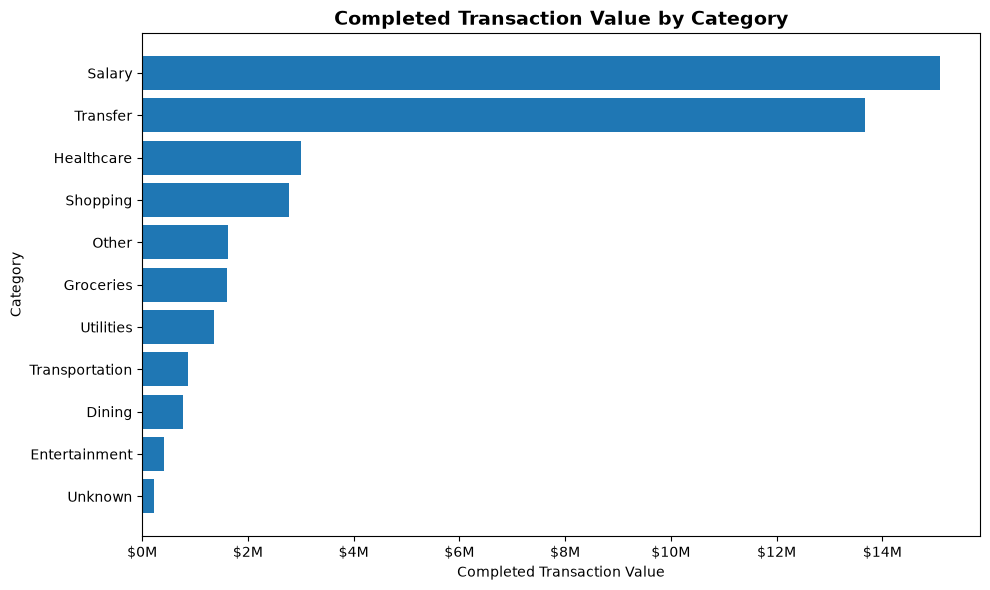

In [22]:
completed_value_by_category = (
    completed_category_analysis
    .sort_values("total_amount", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    completed_value_by_category.index,
    completed_value_by_category["total_amount"]
)

plt.title(
    "Completed Transaction Value by Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Completed Transaction Value")
plt.ylabel("Category")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.0f}M")
)

plt.tight_layout()
plt.show()

### Completed Transaction Volume by Category

Completed transaction counts are compared across categories to identify which categories generate the greatest transaction frequency.

This complements the transaction value analysis by distinguishing high-frequency categories from categories that generate high dollar value.

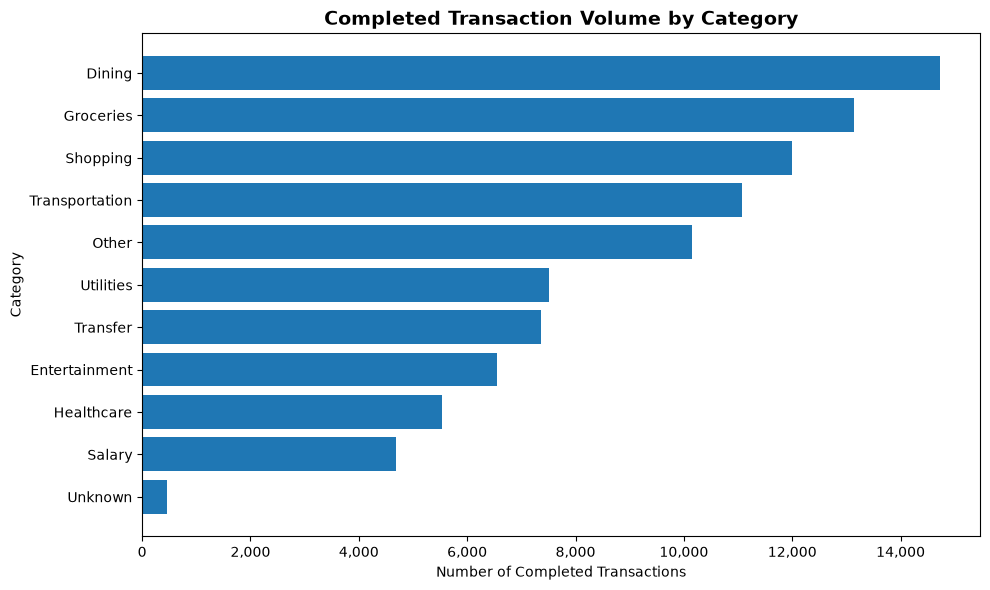

In [23]:
completed_volume_by_category = (
    completed_category_analysis
    .sort_values("transaction_count", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    completed_volume_by_category.index,
    completed_volume_by_category["transaction_count"]
)

plt.title(
    "Completed Transaction Volume by Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Completed Transactions")
plt.ylabel("Category")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()

### Completed Category Insights

Completed transaction activity demonstrates a clear distinction between transaction frequency and financial value.

**Dining** generates the highest completed transaction volume with **14,729 transactions**, followed by **Groceries** with **13,142 transactions**. However, these high-frequency categories have relatively low average transaction amounts.

In contrast, **Salary** accounts for only **4,694 completed transactions** but generates the highest gross completed transaction value at approximately **\$15.09 million**. **Transfer** activity also represents substantial completed financial value at approximately **\$13.68 million**, despite having considerably fewer transactions than the highest-volume spending categories.

These results demonstrate that transaction frequency alone does not indicate financial significance. Evaluating both transaction count and transaction value provides a more complete view of transaction activity.

> Because the dataset is synthetic, these patterns demonstrate analytical techniques and should not be interpreted as evidence of actual consumer financial behavior.

### Completed Transfer Activity

Transfer transactions can represent either incoming or outgoing financial activity. Completed Transfer transactions are therefore analyzed separately by transaction type to understand the direction of transfer activity.

This analysis compares transaction frequency, gross transaction value, average transaction size, and signed transaction value for incoming and outgoing completed Transfers.

In [24]:
completed_transfer_analysis = (
    completed_df[
        completed_df["category"] == "Transfer"
    ]
    .groupby("transaction_type")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        signed_amount=("signed_amount", "sum")
    )
)


In [25]:
completed_transfer_display = completed_transfer_analysis.copy()

completed_transfer_display["transaction_count"] = (
    completed_transfer_display["transaction_count"]
    .map("{:,.0f}".format)
)

for column in [
    "total_amount",
    "average_amount",
    "signed_amount"
]:
    completed_transfer_display[column] = (
        completed_transfer_display[column]
        .map(format_currency)
    )

completed_transfer_display

,transaction_count,total_amount,average_amount,signed_amount
transaction_type,,,,
Credit,"2,935","$5,494,623.77","$1,872.10","$5,494,623.77"
Debit,"4,423","$8,184,064.25","$1,850.34","-$8,184,064.25"


In [26]:
net_transfer_flow = completed_transfer_analysis["signed_amount"].sum()

formatted_net_transfer_flow = (
    f"-${abs(net_transfer_flow):,.2f}"
    if net_transfer_flow < 0
    else f"${net_transfer_flow:,.2f}"
)

print(
    "Net completed Transfer flow:",
    formatted_net_transfer_flow
)

Net completed Transfer flow: -$2,689,440.48


### Transfer Interpretation

Completed Transfer activity contains both incoming Credits and outgoing Debits.

Outgoing Transfer transactions occur more frequently than incoming Transfer transactions, while their average transaction amounts are relatively similar. As a result, completed Transfer activity produces a negative net signed transaction value of approximately **-\$2.69 million**.

The negative value indicates that completed outgoing Transfer value exceeds completed incoming Transfer value within this dataset. It does **not** represent a financial loss, because signed transaction value measures transaction direction rather than profitability.

> Because the dataset is synthetic, these results demonstrate the analytical approach and should not be interpreted as actual customer financial behavior.

## 7. Monthly Transaction Trends

Monthly trend analysis examines how completed transaction activity changes over time.

Because the dataset ends on **September 25, 2026**, September 2026 represents a partial month. It is retained in the dataset but excluded from complete-month trend comparisons to avoid comparing a partial month with full calendar months.

The analysis focuses on completed transactions and evaluates transaction volume, average daily activity, and gross transaction value over time.

In [27]:
monthly_analysis = (
    completed_df
    .set_index("transaction_date")
    .resample("ME")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        signed_amount=("signed_amount", "sum")
    )
    .reset_index()
)

### Complete-Month Analysis

September 2026 contains only partial-month data and is therefore excluded from comparisons intended to evaluate monthly trends.

The original monthly dataset remains unchanged, while a separate `complete_months` analytical view is created for January 2025 through August 2026.

In [28]:
complete_months = monthly_analysis[
    monthly_analysis["transaction_date"] < "2026-09-01"
].copy()

print(
    "Complete months analyzed:",
    len(complete_months)
)

print(
    "Complete-month date range:",
    complete_months["transaction_date"].min().strftime("%b %Y"),
    "to",
    complete_months["transaction_date"].max().strftime("%b %Y")
)

Complete months analyzed: 20
Complete-month date range: Jan 2025 to Aug 2026


### Average Daily Completed Transaction Volume

Monthly transaction counts are influenced by the number of calendar days in each month. To make transaction activity more comparable across months, completed transaction volume is normalized by the number of days in each month.

Average daily transaction volume provides a more consistent measure of underlying transaction activity than raw monthly counts alone.

In [29]:
complete_months["days_in_month"] = (
    complete_months["transaction_date"].dt.days_in_month
)

complete_months["avg_transactions_per_day"] = (
    complete_months["transaction_count"]
    / complete_months["days_in_month"]
)

complete_months[
    [
        "transaction_date",
        "transaction_count",
        "days_in_month",
        "avg_transactions_per_day"
    ]
]

,transaction_date,transaction_count,days_in_month,avg_transactions_per_day
0,2025-01-31,4541,31,146.48
1,2025-02-28,4161,28,148.61
2,2025-03-31,4697,31,151.52
3,2025-04-30,4405,30,146.83
4,2025-05-31,4615,31,148.87
5,2025-06-30,4400,30,146.67
6,2025-07-31,4507,31,145.39
7,2025-08-31,4465,31,144.03
8,2025-09-30,4325,30,144.17
9,2025-10-31,4629,31,149.32


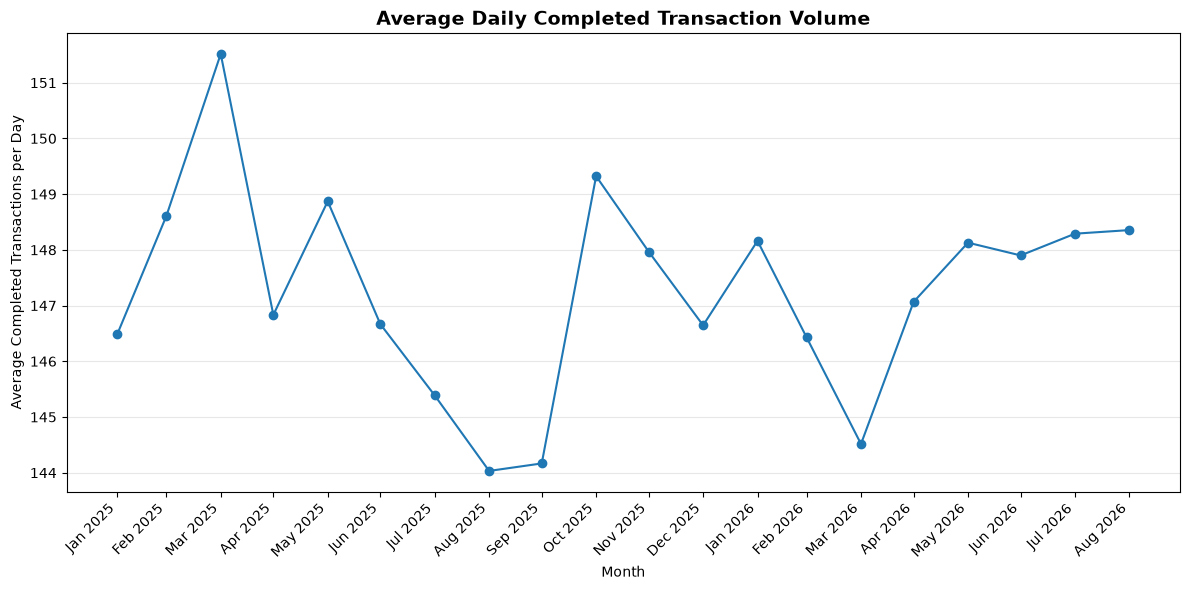

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(
    complete_months["transaction_date"],
    complete_months["avg_transactions_per_day"],
    marker="o"
)

plt.title(
    "Average Daily Completed Transaction Volume",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Completed Transactions per Day")

plt.xticks(
    complete_months["transaction_date"],
    complete_months["transaction_date"].dt.strftime("%b %Y"),
    rotation=45,
    ha="right"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Transaction Volume Trend Interpretation

Average daily completed transaction volume remains relatively stable across the complete-month period, generally ranging around the mid-140s to low-150s transactions per day.

This indicates that differences in raw monthly transaction counts are influenced partly by differences in the number of calendar days rather than by substantial changes in underlying transaction activity.

No strong sustained upward or downward trend is apparent in completed daily transaction volume across the analyzed period.

> Because the dataset is synthetic, these patterns demonstrate time-series analysis techniques and should not be interpreted as evidence of actual customer transaction behavior.

### Monthly Completed Transaction Value

Monthly gross completed transaction value is analyzed to evaluate how the dollar value of finalized transaction activity changes over time.

This analysis uses only complete calendar months from January 2025 through August 2026 so that the partial September 2026 period does not distort month-to-month comparisons.

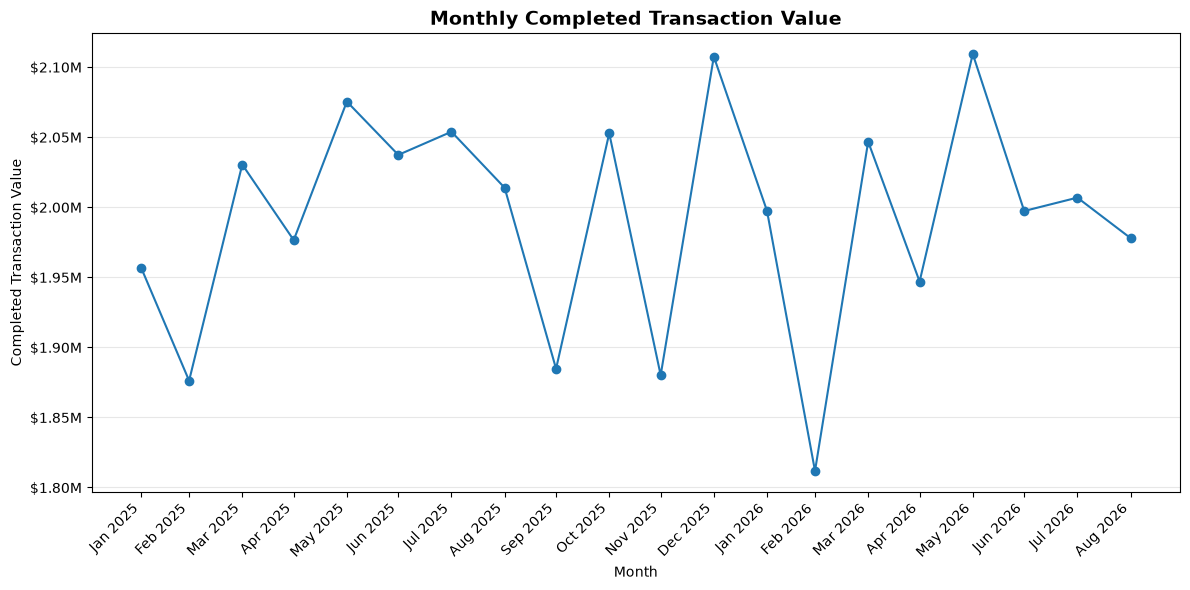

In [40]:
plt.figure(figsize=(12, 6))

plt.plot(
    complete_months["transaction_date"],
    complete_months["total_amount"],
    marker="o"
)

plt.title(
    "Monthly Completed Transaction Value",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Completed Transaction Value")

plt.xticks(
    complete_months["transaction_date"],
    complete_months["transaction_date"].dt.strftime("%b %Y"),
    rotation=45,
    ha="right"
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.2f}M")
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Monthly Transaction Value Interpretation

Gross completed transaction value remains relatively consistent across the complete-month analysis period, generally ranging from approximately **\$1.8 million to \$2.1 million per month**.

Although month-to-month fluctuations are present, the chart does not indicate a clear sustained upward or downward trend in gross completed transaction value.

When considered alongside the relatively stable average daily transaction volume, the results suggest that the synthetic dataset maintains broadly consistent transaction activity over time, with normal variation in both transaction frequency and transaction value.

> These trends reflect the construction of the synthetic dataset and demonstrate time-series analytical techniques rather than actual customer financial behavior.

## 8. Transaction Source Analysis

Transaction source analysis examines where completed transaction activity originates.

The `merchant` field contains both traditional merchants and other transaction sources, such as Employer Payroll and Bank Transfer. Therefore, this section refers to these values collectively as **transaction sources**.

The analysis compares transaction frequency, gross completed transaction value, and average transaction size to identify the sources contributing most heavily to completed transaction activity.

In [32]:
source_analysis = (
    completed_df.groupby("merchant")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)


### Top Transaction Sources by Completed Volume

Completed transaction counts are compared across transaction sources to identify which sources generate the greatest transaction frequency.

The analysis focuses on the top 10 sources to keep the visualization readable while highlighting the largest contributors to transaction volume.

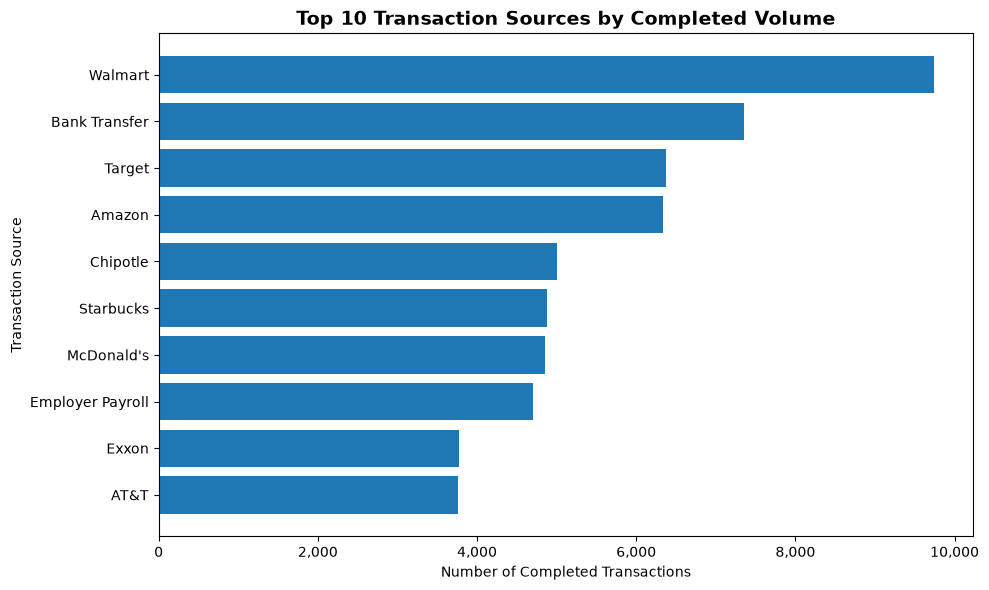

In [33]:
top_sources_by_volume = (
    source_analysis
    .sort_values("transaction_count", ascending=False)
    .head(10)
    .sort_values("transaction_count", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sources_by_volume.index,
    top_sources_by_volume["transaction_count"]
)

plt.title(
    "Top 10 Transaction Sources by Completed Volume",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Completed Transactions")
plt.ylabel("Transaction Source")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()

### Transaction Source Volume Interpretation

Completed transaction volume is distributed across multiple transaction sources, with several retail, dining, transportation, and transfer-related sources generating substantial transaction frequency.

High transaction frequency does not necessarily indicate high financial value. Sources associated with everyday purchases may generate many relatively small transactions, while sources such as Employer Payroll and Bank Transfer may generate fewer but substantially larger transactions.

The next analysis therefore compares transaction sources based on gross completed transaction value.

### Top Transaction Sources by Completed Value

Gross completed transaction value is compared across transaction sources to identify which sources account for the largest dollar volume of finalized transaction activity.

Comparing this result with transaction volume helps distinguish high-frequency sources from high-value sources.

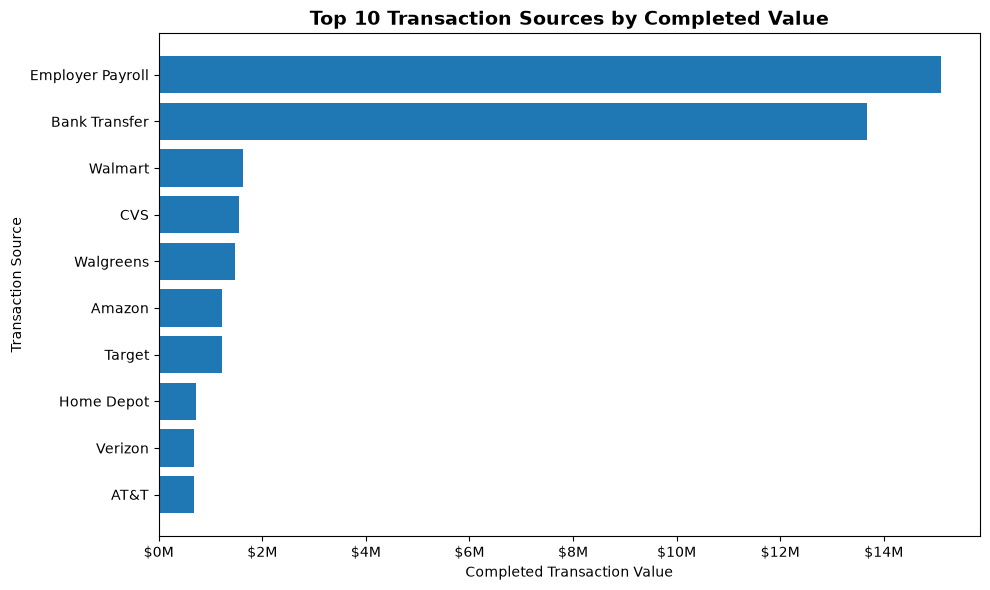

In [34]:
top_sources_by_value = (
    source_analysis
    .sort_values("total_amount", ascending=False)
    .head(10)
    .sort_values("total_amount", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sources_by_value.index,
    top_sources_by_value["total_amount"]
)

plt.title(
    "Top 10 Transaction Sources by Completed Value",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Completed Transaction Value")
plt.ylabel("Transaction Source")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.0f}M")
)

plt.tight_layout()
plt.show()

### Transaction Source Insights

Transaction frequency and transaction value reveal different characteristics of completed transaction activity.

Traditional retail and service sources generate substantial transaction frequency, while **Employer Payroll** and **Bank Transfer** dominate gross completed transaction value because their average transaction sizes are substantially larger.

Employer Payroll represents approximately **\$15.10 million** in completed transaction value, while Bank Transfer represents approximately **\$13.68 million**. This contrasts with many high-frequency retail and service sources whose individual transaction amounts are considerably smaller.

These results reinforce the importance of analyzing both transaction frequency and transaction value when evaluating transaction sources.

> Because the dataset is synthetic, these patterns demonstrate analytical methods and should not be interpreted as actual merchant, employer, banking, or customer behavior.

## 9. Geographic Analysis

Geographic analysis examines the distribution and coverage of completed transactions across U.S. state values.

State values were standardized and validated during the data-cleaning process. Missing or unrecoverable state information was retained as `Unknown` rather than being artificially assigned to a state.

This section evaluates both geographic transaction activity and geographic coverage. Data validity and geographic coverage are treated separately because a dataset can contain only valid state codes without necessarily containing transactions from every U.S. state.

In [35]:
state_analysis = (
    completed_df.groupby("state")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("transaction_count", ascending=False)
)


### Geographic Coverage

Geographic coverage measures how many recognized U.S. states are represented in the completed transaction data.

`Unknown` is excluded when calculating state coverage because it represents transactions for which a valid state could not be recovered.

In [36]:
known_states = completed_df[
    completed_df["state"] != "Unknown"
]["state"]

print("Known states represented:", known_states.nunique())
print(
    "Unknown state transactions:",
    f"{(completed_df['state'] == 'Unknown').sum():,}"
)

Known states represented: 48
Unknown state transactions: 498


In [37]:
all_us_states = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY"
}

represented_states = set(known_states.unique())

missing_states = sorted(
    all_us_states - represented_states
)

print(
    "States not represented:",
    ", ".join(missing_states)
)

States not represented: HI, MT


### Geographic Coverage Interpretation

Completed transactions contain recognized state codes for **48 of the 50 U.S. states**, while **498 transactions** retain an `Unknown` state value because valid geographic information could not be recovered during data cleaning.

The two states not represented in the completed transaction population are **Hawaii (HI)** and **Montana (MT)**.

This distinction is important from a data-quality perspective: the absence of transactions from a state is a **coverage characteristic**, not necessarily a data-validity problem. The represented state values remain valid even though the dataset does not contain activity from every U.S. state.

Similarly, `Unknown` is an intentional data-quality placeholder rather than a missing or null value.

### Top States by Completed Transaction Volume

Completed transaction volume is compared across represented states to identify the geographic areas with the highest transaction frequency.

The visualization focuses on the top 10 states for readability and excludes the `Unknown` category because it does not represent a specific geographic location.

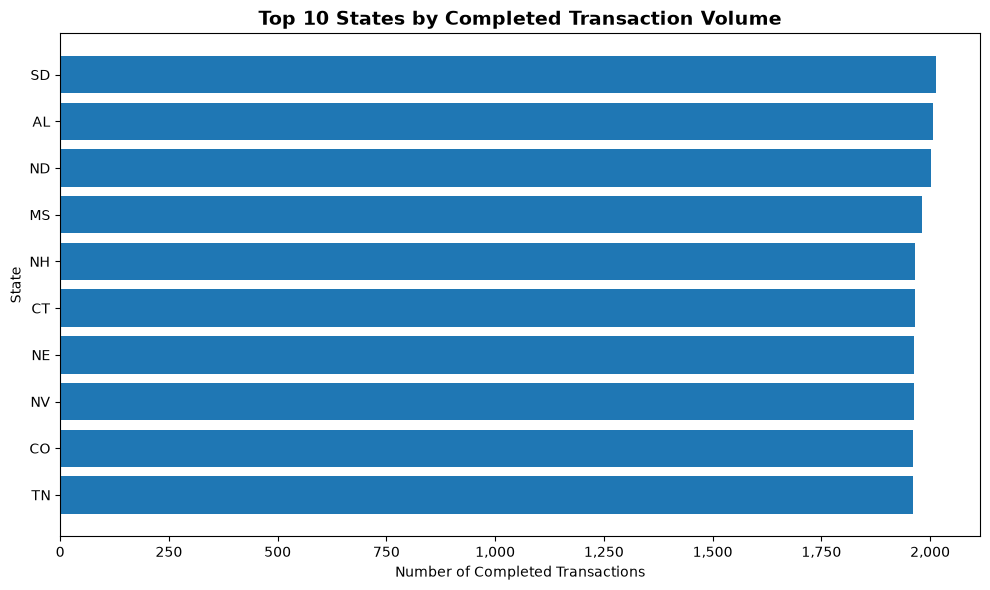

In [38]:
top_states_by_volume = (
    state_analysis
    .drop(index="Unknown", errors="ignore")
    .sort_values("transaction_count", ascending=False)
    .head(10)
    .sort_values("transaction_count", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states_by_volume.index,
    top_states_by_volume["transaction_count"]
)

plt.title(
    "Top 10 States by Completed Transaction Volume",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Completed Transactions")
plt.ylabel("State")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()

### Geographic Distribution Interpretation

Completed transaction activity is distributed across a broad range of represented states rather than being concentrated in only a small number of geographic areas.

Although some states rank higher in completed transaction volume, the differences among the leading states are relatively modest. Therefore, the synthetic dataset does not demonstrate a strong geographic concentration of transaction activity.

The geographic analysis is primarily useful for demonstrating state-level aggregation, coverage assessment, and treatment of `Unknown` geographic values rather than identifying real-world regional behavior.

> Because the dataset is synthetic, geographic patterns should not be interpreted as actual differences in customer activity among U.S. states.

## 10. Key Insights, Limitations, and Conclusion

The analysis transformed the validated transaction dataset into business-oriented insights across transaction categories, processing status, financial direction, time, transaction sources, and geography.

The findings below summarize the primary analytical observations while recognizing that the dataset is synthetic and was created to demonstrate a complete data-cleaning and analytical workflow.

### Key Business Insights

The analysis produced several important observations:

- **Completed transactions dominate the dataset.** Approximately **93.98%** of valid transaction records have a Completed status, allowing completed transactions to serve as the primary population for finalized transaction analysis.

- **Transaction frequency and financial value tell different stories.** Dining generates the highest completed transaction volume with **14,729 transactions**, while Salary generates the highest gross completed transaction value at approximately **\$15.09 million** despite substantially lower transaction frequency.

- **Credit transactions are less frequent but substantially larger.** Debit transactions account for most transaction records, while Credit transactions have much higher average transaction values, largely because Salary and incoming Transfer activity are represented as Credits.

- **Completed Credit and Debit values are closely balanced overall.** Completed Credit activity totals approximately **\$20.70 million**, while completed Debit activity totals approximately **\$20.72 million**, resulting in a net signed transaction value of approximately **-\$11,641.61**.

- **Transfer activity occurs in both directions.** Completed outgoing Transfers exceed incoming Transfers, producing a net signed Transfer value of approximately **-\$2.69 million**.

- **Transaction activity remains relatively stable over time.** Average daily completed transaction volume shows no strong sustained upward or downward trend across the complete-month analysis period. Gross monthly completed transaction value generally remains between approximately **\$1.8 million and \$2.1 million**.

- **Transaction source frequency differs substantially from transaction source value.** Retail and service sources generate substantial transaction frequency, while Employer Payroll and Bank Transfer account for the largest gross completed transaction values because of their larger average transaction sizes.

- **Geographic coverage is broad but not complete.** Completed transactions contain recognized state codes for **48 of the 50 U.S. states**, with Hawaii and Montana not represented. Transactions with unrecoverable state information remain explicitly classified as `Unknown`.

### Analytical Limitations

Several limitations should be considered when interpreting the analysis:

- **Synthetic data:** The dataset was programmatically generated for portfolio purposes. Observed patterns demonstrate analytical methods and should not be interpreted as actual customer, merchant, banking, or consumer behavior.

- **Transaction-level perspective:** The analysis evaluates transaction records rather than complete customer account balances, financial statements, or organizational profitability.

- **Signed transaction value:** Credit values are represented as positive and Debit values as negative for directional analysis. Net signed transaction value therefore represents transaction direction and should not be interpreted as profit, loss, cash flow, or account balance.

- **Reversed transactions:** The dataset does not contain a reliable relationship between a reversed transaction and its corresponding original transaction. Reversed transactions are therefore retained as valid operational records but are not automatically netted against other transactions.

- **Unknown values:** Missing or unrecoverable categorical information was standardized as `Unknown` during data cleaning. These values are retained intentionally to preserve valid transaction records and maintain transparency about data quality.

- **Partial final month:** The dataset ends on September 25, 2026. September 2026 is therefore excluded from complete-month trend comparisons to avoid comparing a partial month with full calendar months.

- **Geographic coverage:** Valid state values are present for 48 states, but Hawaii and Montana are not represented. Absence from the dataset reflects coverage rather than an invalid state-value condition.

### Conclusion

This project demonstrates an end-to-end approach to preparing and analyzing financial transaction data.

The workflow began with raw transaction data containing duplicate records, missing values, inconsistent formatting, invalid dates, invalid amounts, invalid state values, and other data-quality issues. Python and Pandas were used to profile, clean, standardize, and validate the data before producing an analytics-ready dataset.

The cleaned dataset was then analyzed across transaction categories, processing statuses, Debit and Credit direction, completed financial activity, transaction sources, monthly trends, and geographic coverage. Separating gross transaction value from signed transaction direction and distinguishing valid records from finalized transactions allowed the analysis to avoid several common interpretation errors.

The resulting dataset is suitable for downstream SQL analysis and business intelligence reporting. SQL Server provides a structured relational layer for validation and querying, while Power BI and Tableau can extend the project through interactive dashboards and geographic visualizations.

Overall, the project demonstrates practical skills in **data profiling, data cleaning, data validation, Python-based analysis, SQL integration, business interpretation, data visualization, and analytical documentation**.